# Análise Exploratória de Dados — Netflix Daily Top 10

Análise da base Netflix Daily Top 10: tipos de dados, período, tamanho, dados nulos e outliers.

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Carregando os dados

Os rankings usam "-" para valor ausente, então tratamos "-" como nulo já na leitura.

In [13]:
df = pd.read_csv("netflix_daily_top_10.csv", na_values=["-"])
df.head()

,As of,Rank,Year to Date Rank,Last Week Rank,Title,Type,Netflix Exclusive,Netflix Release Date,Days In Top 10,Viewership Score
0,2020-04-01,1,1.0,1.0,"Tiger King: Murder, Mayhem …",TV Show,Yes,"Mar 20, 2020",9,90
1,2020-04-01,2,2.0,NaN,Ozark,TV Show,Yes,"Jul 21, 2017",5,45
2,2020-04-01,3,3.0,2.0,All American,TV Show,NaN,"Mar 28, 2019",9,76
3,2020-04-01,4,4.0,NaN,Blood Father,Movie,NaN,"Mar 26, 2020",5,30
4,2020-04-01,5,5.0,4.0,The Platform,Movie,Yes,"Mar 20, 2020",9,55


## 2. Tamanho da base de dados

In [14]:
linhas, colunas = df.shape
print(f"Linhas: {linhas}")
print(f"Colunas: {colunas}")

Linhas: 7100
Colunas: 10


## 3. Tipos de dados disponíveis

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7100 entries, 0 to 7099
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   As of                 7100 non-null   str    
 1   Rank                  7100 non-null   int64  
 2   Year to Date Rank     6241 non-null   float64
 3   Last Week Rank        3132 non-null   float64
 4   Title                 7100 non-null   str    
 5   Type                  7100 non-null   str    
 6   Netflix Exclusive     4599 non-null   str    
 7   Netflix Release Date  7100 non-null   str    
 8   Days In Top 10        7100 non-null   int64  
 9   Viewership Score      7100 non-null   int64  
dtypes: float64(2), int64(3), str(5)
memory usage: 554.8 KB


In [16]:
df.dtypes

As of                       str
Rank                      int64
Year to Date Rank       float64
Last Week Rank          float64
Title                       str
Type                        str
Netflix Exclusive           str
Netflix Release Date        str
Days In Top 10            int64
Viewership Score          int64
dtype: object

## 4. Período da análise

In [17]:
df["As of"] = pd.to_datetime(df["As of"])
print("Início:", df["As of"].min().date())
print("Fim:   ", df["As of"].max().date())
print("Duração:", (df["As of"].max() - df["As of"].min()).days, "dias")

Início: 2020-04-01
Fim:    2022-03-11
Duração: 709 dias


## 5. Verificando dados nulos

In [18]:
df.isnull().sum()

As of                      0
Rank                       0
Year to Date Rank        859
Last Week Rank          3968
Title                      0
Type                       0
Netflix Exclusive       2501
Netflix Release Date       0
Days In Top 10             0
Viewership Score           0
dtype: int64

In [19]:
print(f"Total de nulos: {df.isnull().sum().sum()}")
print("\nPercentual por coluna (%):")
print((df.isnull().mean() * 100).round(2))

Total de nulos: 7328

Percentual por coluna (%):
As of                    0.00
Rank                     0.00
Year to Date Rank       12.10
Last Week Rank          55.89
Title                    0.00
Type                     0.00
Netflix Exclusive       35.23
Netflix Release Date     0.00
Days In Top 10           0.00
Viewership Score         0.00
dtype: float64


## 6. Outliers

Analisando as colunas numéricas Days In Top 10 e Viewership Score, com boxplots e o método IQR.

In [20]:
df[["Days In Top 10", "Viewership Score"]].describe()

,Days In Top 10,Viewership Score
count,7100.000000,7100.000000
mean,24.123662,122.790141
std,58.473789,213.861642
min,1.000000,1.000000
25%,3.000000,19.000000
50%,7.000000,50.000000
75%,18.000000,128.000000
max,428.000000,1474.000000


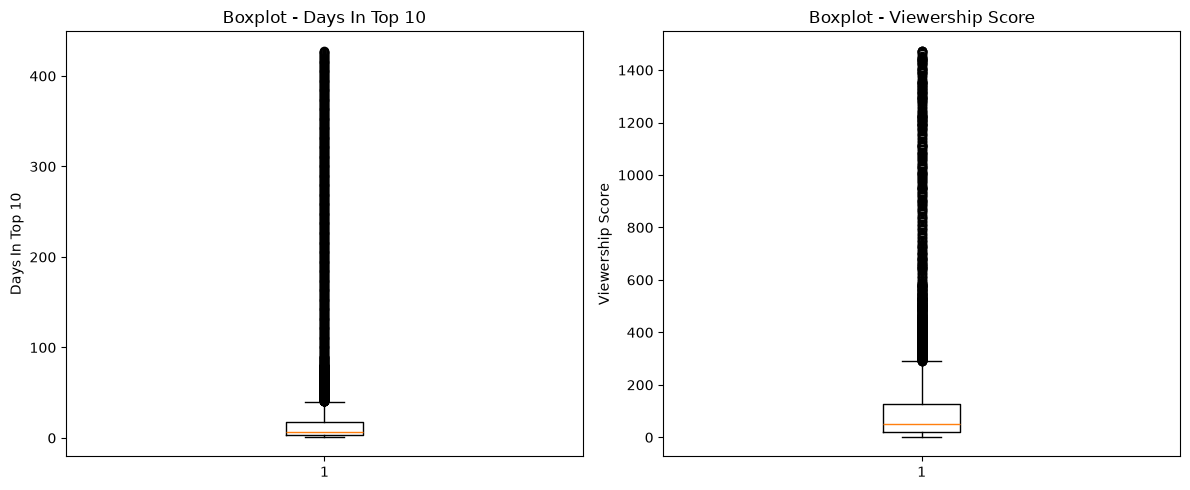

In [21]:
colunas_num = ["Days In Top 10", "Viewership Score"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col in zip(axes, colunas_num):
    ax.boxplot(df[col])
    ax.set_title(f"Boxplot - {col}")
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()

In [22]:
for col in colunas_num:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    outliers = df[(df[col] < lim_inf) | (df[col] > lim_sup)]
    print(f"{col}: {len(outliers)} outliers (limite superior = {lim_sup:.1f})")

Days In Top 10: 743 outliers (limite superior = 40.5)
Viewership Score: 698 outliers (limite superior = 291.5)


## Conclusões

- A base tem 7.100 registros e 10 colunas, de 01/04/2020 a 11/03/2022.
- Os tipos incluem datas, rankings e pontuações (numéricos) e título/tipo (texto).
- Há nulos relevantes em Netflix Exclusive, Last Week Rank e Year to Date Rank.
- Days In Top 10 e Viewership Score têm muitos outliers superiores: títulos que ficaram muito tempo no top 10.